## Titanic Passenger Data

### Brooke Goodrich
Dataset train.csv from Kaggle

### 1. Inspect Data Structure, Types, Missingness, and Outliers

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("train.csv")

In [2]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


In [3]:
print("Rows and columns:", df.shape)
print()
print("Column names:")
print(df.columns.tolist())

Rows and columns: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [4]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

### 1.2 Numerical and categorical variables

In [5]:
numeric_as_stored = df.select_dtypes(include="number").columns.tolist()
text_as_stored = df.select_dtypes(exclude="number").columns.tolist()

print("Stored as numbers:", numeric_as_stored)
print("Stored as text:   ", text_as_stored)

Stored as numbers: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Stored as text:    ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


#### The storage type is not the same as the meaning of the variable, so I classified the columns by what they meant

Numerical: Age, Fare(measurements), SibSp, Parch (counts of family members)
Categorical stored as numbers: Survived, Pclass
Categorical stored as text: Sex, Embarked, Cabin, Ticket
Identifiers: PassengerId, Name

### 1.3 Missing Values

In [6]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)

missing

,missing_count,missing_percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
SibSp,0,0.00
Parch,0,0.00


### 1.4 Duplicate records

In [7]:
print("Fully duplicated rows:", df.duplicated().sum())
print("REpeated PassengerId values:", df["PassengerId"].duplicated().sum())

Fully duplicated rows: 0
REpeated PassengerId values: 0


### 1.5 Potential outliers in Age and Fare (IQR method)

In [8]:
age_q1 = df["Age"].quantile(0.25)
age_q3 = df["Age"].quantile(0.75)
age_iqr = age_q3 - age_q1
age_low = age_q1 - 1.5 * age_iqr
age_high = age_q3 + 1.5 * age_iqr

print("Age Q1:", age_q1)
print("Age Q3:", age_q3)
print("Age IQR:", age_iqr)
print("Age lower fence:", age_low)
print("Age upper fence:", age_high)

Age Q1: 20.125
Age Q3: 38.0
Age IQR: 17.875
Age lower fence: -6.6875
Age upper fence: 64.8125


In [9]:
age_outliers = df[(df["Age"] < age_low) | (df["Age"] > age_high)]

print("Number of Age outliers:", len(age_outliers))
age_outliers[["PassengerId", "Name", "Age", "Pclass", "Survived"]].sort_values("Age")

Number of Age outliers: 11


,PassengerId,Name,Age,Pclass,Survived
54,55,"Ostby, Mr. Engelhart Cornelius",65.00,1,0
280,281,"Duane, Mr. Frank",65.00,3,0
456,457,"Millet, Mr. Francis Davis",65.00,1,0
33,34,"Wheadon, Mr. Edward H",66.00,2,0
672,673,"Mitchell, Mr. Henry Michael",70.00,2,0
745,746,"Crosby, Capt. Edward Gifford",70.00,1,0
116,117,"Connors, Mr. Patrick",70.50,3,0
96,97,"Goldschmidt, Mr. George B",71.00,1,0
493,494,"Artagaveytia, Mr. Ramon",71.00,1,0
851,852,"Svensson, Mr. Johan",74.00,3,0


In [10]:
fare_q1 = df["Fare"].quantile(0.25)
fare_q3 = df["Fare"].quantile(0.75)
fare_iqr = fare_q3 - fare_q1
fare_low = fare_q1 - 1.5 * fare_iqr
fare_high = fare_q3 + 1.5 * fare_iqr

print("Fare Q1:", fare_q1)
print("Fare Q3:", fare_q3)
print("Fare IQR:", fare_iqr)
print("Fare lower fence:", fare_low)
print("Fare higher fence:", fare_high)

Fare Q1: 7.9104
Fare Q3: 31.0
Fare IQR: 23.0896
Fare lower fence: -26.724
Fare higher fence: 65.6344


In [11]:
fare_outliers = df[(df["Fare"] < fare_low) | (df["Fare"] > fare_high)]

print("Number of Fare outliers:", len(fare_outliers))
print("Passenegers with a fare of 0:", (df["Fare"] == 0).sum())

fare_outliers[["PassengerId", "Name", "Pclass", "Fare", "Ticket"]].sort_values("Fare", ascending=False).head(10)

Number of Fare outliers: 116
Passenegers with a fare of 0: 15


,PassengerId,Name,Pclass,Fare,Ticket
679,680,"Cardeza, Mr. Thomas Drake Martinez",1,512.33,PC 17755
258,259,"Ward, Miss. Anna",1,512.33,PC 17755
737,738,"Lesurer, Mr. Gustave J",1,512.33,PC 17755
341,342,"Fortune, Miss. Alice Elizabeth",1,263.00,19950
438,439,"Fortune, Mr. Mark",1,263.00,19950
88,89,"Fortune, Miss. Mabel Helen",1,263.00,19950
27,28,"Fortune, Mr. Charles Alexander",1,263.00,19950
311,312,"Ryerson, Miss. Emily Borie",1,262.38,PC 17608
742,743,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.38,PC 17608
118,119,"Baxter, Mr. Quigg Edmond",1,247.52,PC 17558


### What I found
#### The DataSet has 891 rows and 12 columns, seven columns are stored as numbers and 5 as text
#### There are no duplicates and each PassengerId is unique, Three columns have missing values: Cabin, Age and Embarked
#### 15 passengers have a Fare of 0
#### Age: the IQR fences are roughly −6.7 and 64.8 years. No one falls below the lower fence, and only 11 passengers (ages 65 to 80) fall above the upper one. These are plausible ages, not errors.
#### Columns with missing values: Cabin (687 missing, about 77%), Age (177 missing, about 20%), and Embarked (2 missing, about 0.2%). All other columns are complete.

## 2. Clean and Validate the Dataset
### 2.1 Copy the original DataFrame

In [12]:
df_clean = df.copy()

### 2.2 Missing Values
**Embarked (2 missing): fill with the most common port.**
#### Only 2 rows are affected so it shouldn't have too big of an impact

In [13]:
embarked_mode = df_clean["Embarked"].mode()[0]
print("Most common port:", embarked_mode)

df_clean["Embarked"] = df_clean["Embarked"].fillna(embarked_mode)
print("Embarked still missing:", df_clean["Embarked"].isna().sum())

Most common port: S
Embarked still missing: 0


**Cabin (about 77% missing): keep the column, do not fill in guesses.**

In [14]:
#Flag cabin, label blanks
df_clean["Has_Cabin"] = df_clean["Cabin"].notna().astype(int)
df_clean["CAbin"] = df_clean["Cabin"].fillna("Unknown")

(df_clean.groupby("Pclass")["Has_Cabin"].mean() * 100).round(1)

Pclass
1   81.50
2    8.70
3    2.40
Name: Has_Cabin, dtype: float64

**Age (about 20% missing): fill with the median age of passengers of the same class and sex.**

In [15]:
df_clean.groupby(["Pclass", "Sex"])["Age"].median()

Pclass  Sex   
1       female   35.00
        male     40.00
2       female   28.00
        male     30.00
3       female   21.50
        male     25.00
Name: Age, dtype: float64

In [16]:
df_clean["Age_Missing"] = df_clean["Age"].isna().astype(int)

group_median = df_clean.groupby(["Pclass", "Sex"])["Age"].transform("median")
df_clean["Age"] = df_clean["Age"].fillna(group_median)

print("Ages filled in:", df_clean["Age_Missing"].sum())
print("Age still missing:", df_clean["Age"].isna().sum())

Ages filled in: 177
Age still missing: 0


### 2.3 Outliers

In [17]:
print("Youngest:", df_clean["Age"].min())
print("Oldest:", df_clean["Age"].max())

print("High-fare passengers by class:")
print(df_clean[df_clean["Fare"] > fare_high]["Pclass"].value_counts().sort_index())

Youngest: 0.42
Oldest: 80.0
High-fare passengers by class:
Pclass
1    104
2      5
3      7
Name: count, dtype: int64


In [18]:
df_clean[df_clean["Fare"] == 0][["PassengerId", "Name", "Pclass", "Ticket", "Fare"]]

,PassengerId,Name,Pclass,Ticket,Fare
179,180,"Leonard, Mr. Lionel",3,LINE,0.00
263,264,"Harrison, Mr. William",1,112059,0.00
271,272,"Tornquist, Mr. William Henry",3,LINE,0.00
277,278,"Parkes, Mr. Francis ""Frank""",2,239853,0.00
302,303,"Johnson, Mr. William Cahoone Jr",3,LINE,0.00
413,414,"Cunningham, Mr. Alfred Fleming",2,239853,0.00
466,467,"Campbell, Mr. William",2,239853,0.00
481,482,"Frost, Mr. Anthony Wood ""Archie""",2,239854,0.00
597,598,"Johnson, Mr. Alfred",3,LINE,0.00
633,634,"Parr, Mr. William Henry Marsh",1,112052,0.00


In [19]:
df_clean["Fare_Outlier"] = (df_clean["Fare"] > fare_high).astype(int)
df_clean["Fare_Zero"] = (df_clean["Fare"] == 0).astype(int)

df_clean[["Fare_Outlier", "Fare_Zero"]].sum()

Fare_Outlier    116
Fare_Zero        15
dtype: int64

### 2.4 Data Types
#### Pclass, Sex, and Embarked are categories, so they should be stored as categories
#### Survived will stay as 0/1 to find the survival rate

In [20]:
df_clean["Pclass"] = pd.Categorical(df_clean["Pclass"], categories=[1, 2, 3], ordered=True)
df_clean["Sex"] = df_clean["Sex"].astype("category")
df_clean["Embarked"] = df_clean["Embarked"].astype("category")

df_clean.dtypes

PassengerId        int64
Survived           int64
Pclass          category
Name                 str
Sex             category
Age              float64
SibSp              int64
Parch              int64
Ticket               str
Fare             float64
Cabin                str
Embarked        category
Has_Cabin          int64
CAbin                str
Age_Missing        int64
Fare_Outlier       int64
Fare_Zero          int64
dtype: object

### 2.5 Validate the cleaned dataset

In [21]:
print("Shape before cleaning:", df.shape)
print("Shape after cleaning: ", df_clean.shape)
print()
print("Missing values after cleaning:")
print(df_clean.isna().sum())
print()
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Shape before cleaning: (891, 12)
Shape after cleaning:  (891, 17)

Missing values after cleaning:
PassengerId       0
Survived          0
Pclass            0
Name              0
Sex               0
Age               0
SibSp             0
Parch             0
Ticket            0
Fare              0
Cabin           687
Embarked          0
Has_Cabin         0
CAbin             0
Age_Missing       0
Fare_Outlier      0
Fare_Zero         0
dtype: int64

Duplicate rows after cleaning: 0


### Summary of cleaning decisions
#### With only 2 missing it is a small number and you still keep the passengers with impute mode.
#### Made a second copy of the dataframe so as not to damage the original and for comparison
#### Used a pandas command to leave every other cell alone
#### groupby split the passengers into class and sex group and transform gives each row its own group median so it lines up with the blanks
#### Used condition.astype(int) to keep rows and find them
#### .astype("category") tells pandas that Sex, Embarked, and Pclass are labels not free text or quantities
#### .isna().sum(), .duplicated().sum(), .shape use as checks to show that problems are gone

## 3. Compute Descriptive Statistics
### 3.1 Age and Fare

In [22]:
for col in ["Age", "Fare"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    print(col)
    print(" Mean:    ", round(df_clean[col].mean(), 2))
    print(" Median:  ", round(df_clean[col].median(), 2))
    print(" Minimum: ", round(df_clean[col].min(), 2))
    print(" Maximum: ", round(df_clean[col].max(), 2))
    print(" Range:   ", round(df_clean[col].max() - df_clean[col].min(), 2))
    print(" Variance:", round(df_clean[col].var(), 2))
    print(" Std dev: ", round(df_clean[col].std(), 2))
    print(" Q1:      ", round(q1, 2))
    print(" Q3:      ", round(q3, 2))
    print(" IQR:     ", round(q3 - q1, 2))
    print()



Age
 Mean:     29.11
 Median:   26.0
 Minimum:  0.42
 Maximum:  80.0
 Range:    79.58
 Variance: 177.01
 Std dev:  13.3
 Q1:       21.5
 Q3:       36.0
 IQR:      14.5

Fare
 Mean:     32.2
 Median:   14.45
 Minimum:  0.0
 Maximum:  512.33
 Range:    512.33
 Variance: 2469.44
 Std dev:  49.69
 Q1:       7.91
 Q3:       31.0
 IQR:      23.09



### 3.2 Frequency and percentage for Sex, Pclass, and Survived

In [23]:
for col in ["Sex", "Pclass", "Survived"]:
    counts = df_clean[col].value_counts().sort_index()
    percents = (df_clean[col].value_counts(normalize=True).sort_index() * 100).round(2)

    print(pd.DataFrame({"count": counts, "percent": percents}))
    print()

        count  percent
Sex                   
female    314    35.24
male      577    64.76

        count  percent
Pclass                
1         216    24.24
2         184    20.65
3         491    55.11

          count  percent
Survived                
0           549    61.62
1           342    38.38



### 3.3 Average Fare by passenger class

In [24]:
df_clean.groupby("Pclass", observed=True)["Fare"].agg(["mean", "median"])

,mean,median
Pclass,,
1,84.15,60.29
2,20.66,14.25
3,13.68,8.05


### Findings
#### there were more male passengers than female, 24% of passengers were in 1st class, 20% were in 2nd class and 55% percent were in 3rd class
#### 61.62% of passengers did not survive and 38.38% did survive
#### Mean age was 29 with a median of 26
#### Max fare was $512 with $0 being recorded for lowest fare, though we don't know why these passengers fare was $0

## 4. Visualize Patterns and Investigate Anomalies
### 4.1 Histogram: distribution of Age

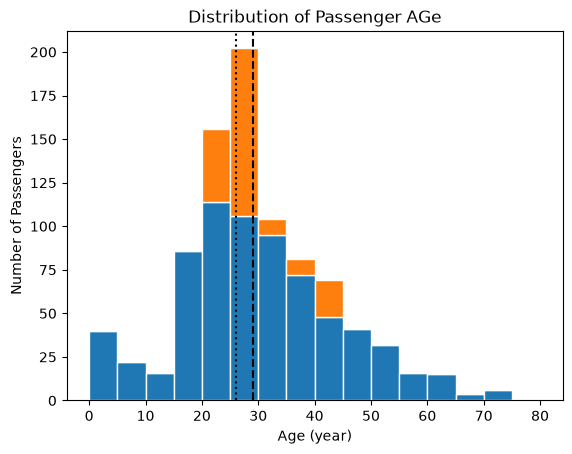

In [25]:
recorded_age = df_clean[df_clean["Age_Missing"] == 0]["Age"]
filled_age = df_clean[df_clean["Age_Missing"] == 1]["Age"]

plt.hist([recorded_age, filled_age], bins=range(0, 85, 5), stacked=True,
         label=["Recorded age", "Filled-in age"], edgecolor="White")
plt.axvline(df_clean["Age"].mean(), color="black", linestyle="--", label="Mean")
plt.axvline(df_clean["Age"].median(), color="black", linestyle=":", label="Median")
plt.title("Distribution of Passenger AGe")
plt.xlabel("Age (year)")
plt.ylabel("Number of Passengers")
plt.show()

#### Filled in ages appear in orange and recorded ages in blue, the filled in ages I think would need further investigation as these numbers are based on the highest and lowest age and the mean and median of age of passengers recorded
#### The filled in ages are more concetrated on the mean and median of ages of passengers


### 4.2 Boxplot: Fare

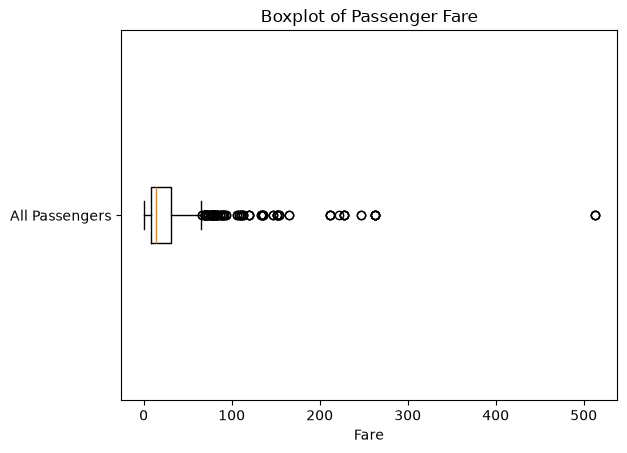

In [26]:
plt.boxplot(df_clean["Fare"], orientation="horizontal")
plt.title("Boxplot of Passenger Fare")
plt.xlabel("Fare")
plt.yticks([1], ["All Passengers"])
plt.show()

#### This graph shows the range of prices for fare
#### The 3 highest fares all had the same ticket number suggesting these tickets could be a total of all 3 or 4 in the case of the 1 and second highest tickets-so it is unclear if we truly know the highest ticket price for the Titanic

### 4.3 Bar Chart: passengers by class

Pclass
1    216
2    184
3    491
Name: count, dtype: int64


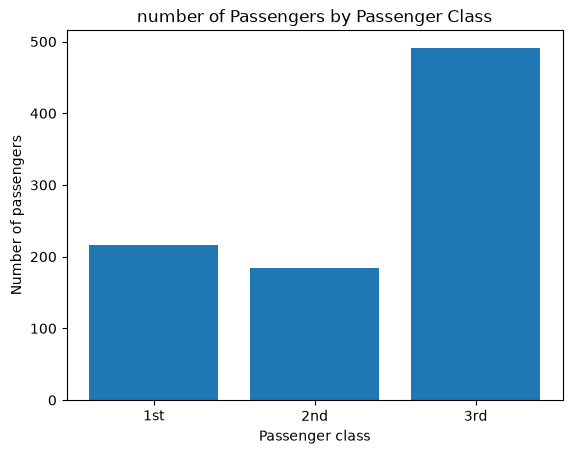

In [27]:
class_counts = df_clean["Pclass"].value_counts().sort_index()
print(class_counts)

plt.bar(["1st", "2nd", "3rd"], class_counts.values)
plt.title("number of Passengers by Passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Number of passengers")
plt.show()

#### 3rd class had the largest number of passengers with 2nd class having the lowest
#### There were no missing values for the data on passenger class 

### 4.4 Grouped bar chart: survival rate by class and sex

Sex     female  male
Pclass              
1        96.80 36.90
2        92.10 15.70
3        50.00 13.50


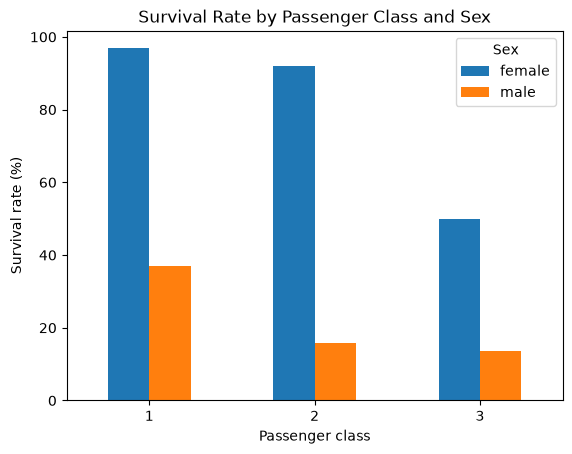

In [28]:
survival_rate = df_clean.groupby(["Pclass", "Sex"], observed=True)["Survived"].mean().unstack() * 100
print(survival_rate.round(1))

survival_rate.plot(kind="bar", rot=0)
plt.title("Survival Rate by Passenger Class and Sex")
plt.xlabel("Passenger class")
plt.ylabel("Survival rate (%)")
plt.legend(title="Sex")
plt.show()

#### More women survived in every passenger class by a significant margin
#### Almost all the women from first and second class survived, while 3rd class women suffered the largest loss
#### 3rd class suffered the largest losses overall 
#### More men survived in first class than any other while second and third were close percentage wise
#### the steep rate of decline for survival between the women among the class would warrant further investigation to see why the numbers were so different

#### The Titanic training data contains 891 passengers and 12 variables, with no duplicate records but substantial missing data in Cabin (about 77%) and Age (about 20%), plus two missing values in Embarked. I kept every passenger: Embarked was filled with the most common port, Cabin was kept with an "Unknown" label and a Has_Cabin indicator, and Age was imputed with the median for each class and sex and flagged. Age is fairly symmetric with a mild right skew, while Fare is strongly right-skewed, with a mean more than twice its median and many high values that are real first-class and shared-ticket fares, so they were retained and flagged instead of removed. Third class made up more than half of the passengers, and average fare fell steeply from first to third class. Only about 38% of passengers survived, and survival was much higher for women than men and for first class than third. The main limitations are that one in five ages is an estimate, which makes the age distribution look more concentrated than it truly was, and that Cabin is too incomplete to analyze directly. Fare also appears to be recorded per ticket and not per person, the zero fares are unexplained, and this file covers only part of the ship's passengers, so the findings describe associations in this sample and not causes. The Data only tells you half the story, without context this data only means so much. 